# Wykład 9 — Więcej wymiarów i pamięć na żądanie

Tabela pomiarów ma dwa indeksy: jeden wybiera wiersz, drugi kolumnę. Zaczniemy od odczytania pojedynczej wartości, potem przekażemy całą tabelę funkcji. Na koniec wczytamy plik z punktami, którego rozmiar poznamy dopiero po otwarciu.

Przydadzą się pętle, tablice jednowymiarowe i wskaźniki. Każda komórka C jest osobnym programem.

## W9.1 — Czy tablica musi być jednowymiarowa?

Dwie stacje zapisują po trzy pomiary. W tablicy `int tab[2][3]` pierwszy indeks wybiera stację, a drugi pomiar. Klamry wewnętrzne grupują wartości należące do jednej stacji.

W zapisie `{{11, 12, 13}, {21, 22, 23}}` pierwsza grupa inicjalizuje wiersz 0, a druga wiersz 1. Indeksy zaczynają się od zera. Dla dwóch wierszy i trzech kolumn mamy `0 <= i < 2` oraz `0 <= j < 3`.

**Przewidź:** jaki wynik da pierwszy odczyt `tab[1][2]`? Która liczba zmieni się w tabeli?

In [ ]:
#include <stdio.h>

int main(void)
{
    int tab[2][3] = {{11, 12, 13}, {21, 22, 23}};

    printf("Przed zapisem: %d\n", tab[1][2]);
    tab[1][2] = 29;
    for (int i = 0; i < 2; ++i) {
        for (int j = 0; j < 3; ++j)
            printf("%3d", tab[i][j]);
        putchar('\n');
    }
    return 0;
}

**Interpretacja.** Przed zapisem odczytujemy 23. Po zapisie pierwszy wiersz nadal zawiera 11, 12, 13. W drugim widzimy 21, 22, 29. Wewnętrzna pętla odczytuje cały wiersz, a zewnętrzna wybiera następny.

**Zmień.** Zapisz 99 w pierwszym wierszu i drugiej kolumnie. Wskaż oba indeksy przed uruchomieniem.

## W9.2 — Jak komputer przechowuje tabelę?

Tablica 2D jest tablicą wierszy. Za ostatnim elementem pierwszego wiersza w pamięci zaczyna się drugi wiersz. Ile bajtów zajmuje całość, a ile jeden wiersz?

Dla $R$ wierszy, $C$ kolumn i elementów typu `T` rozmiar całej tablicy to $R C\,\operatorname{sizeof}(T)$ bajtów. Element `tab[i][j]` poprzedza $i$ pełnych wierszy oraz $j$ elementów bieżącego wiersza. Jego przesunięcie od początku całej tablicy wynosi

$$
(iC+j)\,\operatorname{sizeof}(T).
$$

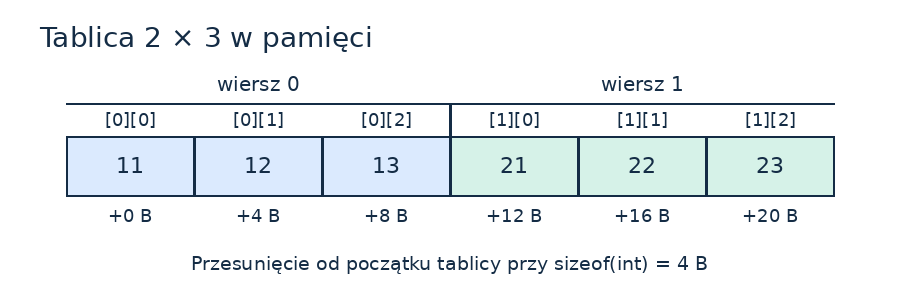

**Przewidź:** ile elementów poprzedza `tab[1][1]`? Porównaj adresy wydrukowane przez ten program. Rozmiary sprawdź przez `sizeof`.

In [ ]:
#include <stdio.h>

int main(void)
{
    int tab[2][3] = {{11, 12, 13}, {21, 22, 23}};

    printf("Tablica: %zu B, wiersz: %zu B, element: %zu B\n",
           sizeof tab, sizeof tab[0], sizeof tab[0][0]);
    for (int i = 0; i < 2; ++i)
        for (int j = 0; j < 3; ++j)
            printf("[%d][%d] = %d, adres %p\n",
                   i, j, tab[i][j], (void *)&tab[i][j]);
    return 0;
}

**Interpretacja.** Układ w kolejności wierszy (ang. *row-major*) daje cztery elementy przed `tab[1][1]`. Przy typowym dla naszego Linux/GCC rozmiarze `int` równym 4 B daje to 16 B przesunięcia, a rozmiary tablicy, wiersza i elementu to odpowiednio 24, 12 i 4 B. Kod używa `%zu` dla wyniku `sizeof` i `%p` z argumentem typu `void *` dla adresu.

**Zmień.** Porównaj odległość w bajtach od `tab[0][2]` do `tab[1][2]` z rozmiarem wiersza, licząc z wzoru. Zmiana indeksu wiersza daje taki sam krok dla każdej kolumny.

## W9.3 — Co oznacza przesunięcie o wiersz?

Dodanie 1 do wskaźnika przesuwa go o rozmiar wskazywanego obiektu. Przy tablicy dwuwymiarowej tym obiektem może być cały wiersz albo pojedynczy pomiar.

| Wyrażenie | Typ wskaźnika w tym użyciu | Wskazywany obiekt |
| --- | --- | --- |
| `tab` | `int (*)[3]` | pierwszy wiersz |
| `tab + 1` | `int (*)[3]` | drugi wiersz |
| `tab[0]` | `int *` | pierwszy element pierwszego wiersza |
| `&tab[0][0]` | `int *` | ten sam element |

Sama tablica ma typ `int [2][3]`. W typowym wyrażeniu `tab` konwertuje się na wskaźnik do swojego pierwszego elementu, którym jest wiersz. `int **` wskazywałby na obiekt typu `int *`, a nasze wiersze zawierają liczby `int`.

**Przewidź:** do jakich obiektów prowadzą `p + 1` i `q + 1`? Jakie rozmiary mają te obiekty?

In [ ]:
#include <stdio.h>

int main(void)
{
    int tab[2][3] = {{11, 12, 13}, {21, 22, 23}};
    int (*p)[3] = tab;
    int *q = &tab[0][0];

    printf("Wiersz: %p -> %p, krok %zu B\n",
           (void *)p, (void *)(p + 1), sizeof *p);
    printf("Element: %p -> %p, krok %zu B\n",
           (void *)q, (void *)(q + 1), sizeof *q);
    printf("Odczyty: %d i %d\n", (*(p + 1))[0], *(q + 1));
    return 0;
}

**Interpretacja.** `p + 1` wskazuje drugi wiersz, więc `(*(p + 1))[0]` daje 21. `q + 1` wskazuje drugą liczbę pierwszego wiersza, więc `*(q + 1)` daje 12. Początkowe adresy z wydruku odpowiadają temu samemu początkowi pamięci, a typ określa rozmiar kroku.

`q + 3` to wskaźnik tuż za końcem pierwszego wiersza. Samo jego utworzenie jest dozwolone. Odczyt `q[3]` ma niezdefiniowane zachowanie. Fizyczne sąsiedztwo wierszy nie pozwala też odejmować wskaźników `int *` do elementów różnych wierszy.

**Zmień.** Odczytaj 23, używając `p` i dwóch indeksów. Który indeks wybierze wiersz?

## W9.4 — Jak przekazać macierz do funkcji?

Funkcja otrzymuje adres pierwszego wiersza i aktywne wymiary. Kiedy przechodzi do następnego wiersza, musi uwzględnić pełną szerokość wiersza, również miejsca poza aktywnym prostokątem.

Obiekt `int tab[MAXROW][MAXCOL]` ma stałą pojemność. Program używa lewego górnego prostokąta o `n` wierszach i `m` kolumnach. Sprawdzamy $0<n\leq\texttt{MAXROW}$ oraz $0<m\leq\texttt{MAXCOL}$ przed zapisem lub odczytem.

Parametr `int A[][MAXCOL]` oznacza tu to samo co `int (*A)[MAXCOL]`. Do przesunięcia o jeden wiersz potrzeba `MAXCOL`, a do wyznaczenia granic pętli potrzeba `n` i `m`. Rozmiaru całej macierzy nie odzyskamy przez `sizeof A` wewnątrz funkcji, ponieważ `A` jest tam wskaźnikiem.

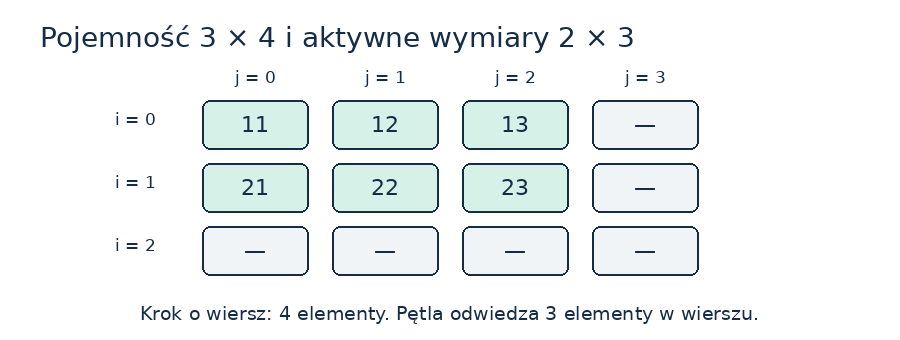

**Przewidź:** ile liczb wypisze program? O ile elementów są od siebie oddalone początki dwóch kolejnych wierszy?

In [ ]:
#include <stdio.h>

#define MAXROW 3
#define MAXCOL 4

void init(int A[][MAXCOL], int n, int m)
{
    for (int i = 0; i < n; ++i)
        for (int j = 0; j < m; ++j)
            A[i][j] = 10 * (i + 1) + j + 1;
}

void print(int A[][MAXCOL], int n, int m)
{
    for (int i = 0; i < n; ++i) {
        for (int j = 0; j < m; ++j)
            printf("%3d", A[i][j]);
        putchar('\n');
    }
}

int main(void)
{
    int tab[MAXROW][MAXCOL];
    int n = 2, m = 3;
    if (n <= 0 || n > MAXROW || m <= 0 || m > MAXCOL) {
        fputs("Niepoprawne wymiary.\n", stderr);
        return 1;
    }

    init(tab, n, m);
    print(tab, n, m);
    return 0;
}

**Interpretacja.** Funkcje pracują na sześciu elementach, rozmieszczonych w dwóch wierszach o fizycznej szerokości czterech elementów. `main` sprawdza wymiary przed wywołaniem obu funkcji. Każdy odczytywany element został zapisany przez `init`.

**Zmień.** Ustaw `n = 3, m = 2`. Porównaj liczbę wypisanych elementów i rozmiar kroku do następnego wiersza.

## W9.5 — Co można zrobić z macierzą?

Możemy wybrać przekątną, wiersz lub kolumnę. Wartości można zapisać w osobnej tablicy, a do istniejącego wiersza można uzyskać dostęp przez jego adres.

Wiersz zawiera `m` aktywnych elementów, kolumna `n`, a przekątna prostokąta kończy się, gdy zabraknie wierszy lub kolumn. Ma więc $\min(n,m)$ elementów. Dla macierzy kwadratowej daje to $n$. Funkcje sprawdzają wymiary, indeks i pojemność bufora przed kopiowaniem. Przy wstawianiu wymagają dokładnie tylu wartości, ile miejsc ma wybrany wiersz lub kolumna. Wywołujący podaje rzeczywistą pojemność bufora po swojej stronie.

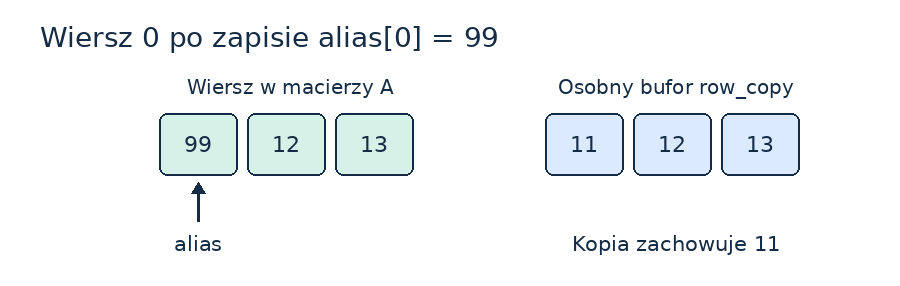

**Przewidź:** po skopiowaniu wiersza 0 zmienimy `alias[0]` na 99. Która tablica zachowa 11? Które elementy znajdą się w przekątnej przed zmianami?

In [ ]:
#include <stdio.h>

#define MAXROW 3
#define MAXCOL 4

int valid(int n, int m)
{
    return 0 < n && n <= MAXROW && 0 < m && m <= MAXCOL;
}

int copy_diagonal(int A[][MAXCOL], int n, int m, int out[], int capacity)
{
    int length = n < m ? n : m;
    if (!valid(n, m) || capacity < length)
        return 0;
    for (int i = 0; i < length; ++i)
        out[i] = A[i][i];
    return 1;
}

int copy_row(int A[][MAXCOL], int n, int m, int row, int out[], int capacity)
{
    if (!valid(n, m) || row < 0 || row >= n || capacity < m)
        return 0;
    for (int j = 0; j < m; ++j)
        out[j] = A[row][j];
    return 1;
}

int copy_column(int A[][MAXCOL], int n, int m, int col, int out[], int capacity)
{
    if (!valid(n, m) || col < 0 || col >= m || capacity < n)
        return 0;
    for (int i = 0; i < n; ++i)
        out[i] = A[i][col];
    return 1;
}

int insert_row(int A[][MAXCOL], int n, int m, int row, const int values[], int length)
{
    if (!valid(n, m) || row < 0 || row >= n || length != m)
        return 0;
    for (int j = 0; j < m; ++j)
        A[row][j] = values[j];
    return 1;
}

int insert_column(int A[][MAXCOL], int n, int m, int col, const int values[], int length)
{
    if (!valid(n, m) || col < 0 || col >= m || length != n)
        return 0;
    for (int i = 0; i < n; ++i)
        A[i][col] = values[i];
    return 1;
}

void print(const char *label, const int a[], int n)
{
    printf("%s", label);
    for (int i = 0; i < n; ++i)
        printf(" %d", a[i]);
    putchar('\n');
}

int main(void)
{
    int A[MAXROW][MAXCOL] = {{11, 12, 13}, {21, 22, 23}};
    int n = 2, m = 3, row = 0;
    int diagonal[MAXROW], row_copy[MAXCOL], col_copy[MAXROW];
    int new_row[] = {41, 42, 43}, new_col[] = {71, 72};
    if (!copy_diagonal(A, n, m, diagonal, MAXROW) ||
        !copy_row(A, n, m, row, row_copy, MAXCOL) ||
        !copy_column(A, n, m, m - 1, col_copy, MAXROW)) {
        fputs("Kopiowanie nie powiodlo sie.\n", stderr);
        return 1;
    }

    int *alias = A[row]; /* indeks sprawdzony przez copy_row */
    alias[0] = 99;
    print("Przekatna:", diagonal, n < m ? n : m);
    print("Kopia wiersza:", row_copy, m);
    print("Wiersz przez alias:", A[row], m);
    print("Kopia ostatniej kolumny:", col_copy, n);

    if (!insert_row(A, n, m, n - 1, new_row, sizeof new_row / sizeof new_row[0]) ||
        !insert_column(A, n, m, m - 1, new_col, sizeof new_col / sizeof new_col[0])) {
        fputs("Wstawianie nie powiodlo sie.\n", stderr);
        return 1;
    }
    for (int i = 0; i < n; ++i)
        print("Po wstawieniu:", A[i], m);
    return 0;
}

**Interpretacja.** Przekątna daje `11 22`. Kopia wiersza ma nadal `11 12 13`, ale w macierzy pierwszy element wynosi już 99. Po wstawieniu wiersza i kolumny otrzymujemy `99 12 71` oraz `41 42 72`. W miejscu przecięcia wygrywa późniejszy zapis. Bufor kopii jest odrębny od macierzy. `alias` wskazuje początek istniejącego wiersza. Można przez niego korzystać z wiersza za życia macierzy. Takiego adresu nie przekazujemy do `free`.

**Zmień.** Przenieś wstawianie kolumny przed wstawianie wiersza i przewidź wartość w miejscu przecięcia. Następnie podaj zbyt krótki bufor wejściowy i sprawdź zwrócony status.

## W9.6 — A jeśli rozmiaru jeszcze nie znamy?

Przy wczytywaniu danych do tablicy o stałej pojemności trzeba z góry ustalić liczbę miejsc. Gdy nagłówek pliku zawiera liczbę pomiarów, możemy dobrać liczbę miejsc podczas działania programu.

Przy pojemności 100 mamy miejsce na 100 wartości, nawet jeśli plik zawiera tylko trzy. Dla 101 pomiarów trzeba odmówić odczytu całego zbioru albo zmienić sposób przechowywania. Jeżeli nagłówek mówi, ile pomiarów nadejdzie, program może sprawdzić tę liczbę i poprosić o tyle miejsc, ile potrzebuje.

Lokalna tablica zadeklarowana bez `static`, jak w naszych przykładach, istnieje do wyjścia z bloku. Blok przydzielony przez `malloc` pozostaje zaalokowany do `free`, niezależnie od zasięgu zmiennej z jego adresem. Do zwolnienia trzeba zachować adres początku. W C11 istnieją tablice o zmiennej długości (VLA), których obsługa zależy od implementacji. Tutaj użyjemy jawnej alokacji bloku.

**Przewidź.** Plik zawiera 101 par współrzędnych. Jeśli `sizeof(double)` daje 8 B, ile bajtów potrzebuje każda z dwóch tablic współrzędnych?

## W9.7 — Jak zamówić i oddać pamięć?

`malloc` przyjmuje rozmiar bloku w bajtach. Po udanej alokacji zapisujemy wartości, korzystamy z nich i oddajemy blok przez `free`.

Deklaracja z `<stdlib.h>` to `void *malloc(size_t size);`. Po powodzeniu otrzymujemy adres początku bloku, a przy niepowodzeniu `NULL`. C pozwala przypisać wynik typu `void *` do `int *` bez rzutowania. W `sizeof *p` chodzi o rozmiar typu `int`. W tym użyciu `sizeof` nie odczytuje pamięci przez `p`.

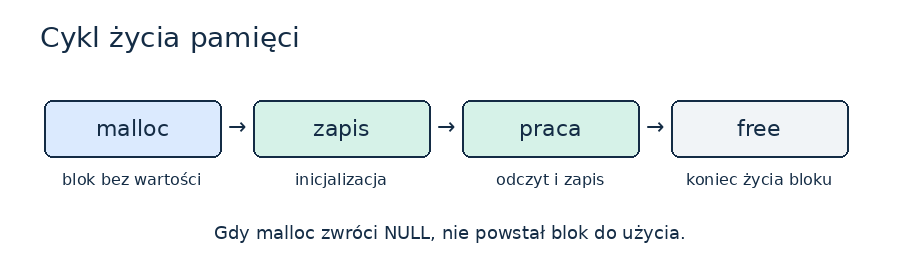

W notebooku podaj jedną liczbę od 1 do 100, zmieniając tekst w `const char *line = "4\n";` i zachowując `\n` na końcu. Gdy uruchamiasz program w terminalu, ustaw `from_keyboard = 1`, wpisz liczbę i naciśnij Enter. W tym trybie `fgets` ogranicza rozmiar odczytu. W obu trybach `strtol` wykrywa błędną liczbę i przekroczenie zakresu. Program odrzuca wiersz dłuższy niż 62 bajty przed znakiem nowej linii, brak tego znaku i dodatkowy tekst. Po sprawdzeniu zakresu `n` sprawdzamy jeszcze, czy mnożenie liczby elementów przez rozmiar elementu zmieści się w `size_t`.

**Przewidź:** dla wejścia 4 jakie będą pierwszy i ostatni element? Przy której kontroli zostanie zatrzymane wejście 0?

In [ ]:
#include <ctype.h>
#include <errno.h>
#include <stdint.h>
#include <stdio.h>
#include <stdlib.h>
#include <string.h>

#define MAX_ELEMENTS 100
#define LINE_SIZE 64

int read_count(const char line[], size_t *n)
{
    char *end;
    if (strlen(line) >= LINE_SIZE || strchr(line, '\n') == NULL)
        return 0;
    errno = 0;
    long value = strtol(line, &end, 10);
    if (end == line || errno == ERANGE || value < 1 || value > MAX_ELEMENTS)
        return 0;
    while (isspace((unsigned char)*end))
        ++end;
    if (*end != '\0')
        return 0;
    *n = (size_t)value;
    return 1;
}

int fits_int_array(size_t n)
{
    return n <= SIZE_MAX / sizeof(int);
}

int main(void)
{
    const int from_keyboard = 0;
    const char *line = "4\n";
    char input[LINE_SIZE];
    if (from_keyboard) {
        puts("Podaj liczbe elementow (1-100):");
        fflush(stdout);
        line = fgets(input, sizeof input, stdin);
        if (line == NULL)
            line = "";
    }

    size_t n;
    if (!read_count(line, &n) || !fits_int_array(n)) {
        fputs("Niepoprawna liczba elementow.\n", stderr);
        return 1;
    }

    int *p = malloc(n * sizeof *p);
    if (p == NULL) {
        fputs("Brak pamieci.\n", stderr);
        return 1;
    }

    for (size_t i = 0; i < n; ++i)
        p[i] = (int)i + 1;
    for (size_t i = 0; i < n; ++i)
        printf("%d%c", p[i], i + 1 == n ? '\n' : ' ');

    free(p);
    return 0;
}

**Interpretacja.** Dla 4 dostajemy `1 2 3 4`. Wejście 0 odrzuca kontrola dodatniego rozmiaru. `malloc` nie inicjalizuje elementów, dlatego najpierw zapisujemy wartości w całym używanym zakresie. Właścicielem bloku jest tutaj `main`, który odpowiada za jedno `free` po udanej alokacji. Funkcja, której pożyczymy adres, może korzystać z bloku za jego życia.

Do `free` przekazujemy adres zwrócony przez `malloc` albo `NULL`. Błędy do rozpoznania na papierze to zwolnienie adresu `p + 1`, zwolnienie lokalnej tablicy, ponowne zwolnienie bloku i odczyt po zwolnieniu. Ustawienie `p = NULL` po `free(p)` zmienia tylko `p`. Inne aliasy nie pozwalają już korzystać ze zwolnionego bloku.

**Zmień.** Zastąp wartość w `line` najpierw przez `"1\n"`, a potem przez `"4 koty\n"`. Wskaż, co w obu przypadkach stanie się przed wywołaniem `malloc`.

## W9.8 — Czy dynamiczna tablica działa jak zwykła?

Funkcja sortująca tablicę jednowymiarową potrzebuje wskaźnika do pierwszego elementu i liczby elementów. Te same argumenty wystarczą, gdy pamięć przydzielono przez `malloc`.

Przy wejściu z klawiatury odczytujemy i sprawdzamy liczbę elementów jak w poprzednim przykładzie. Poniżej liczbę elementów podaje gotowy zestaw pomiarów, żeby za każdym razem porównać te same dane przed sortowaniem i po nim. Przepisujemy je do przydzielonego bloku, a potem wywołujemy `bubble_sort(p, n)`. To ta sama funkcja z W7, łącznie z wcześniejszym zakończeniem po przebiegu bez zamian.

**Przewidź:** jaki porządek otrzymamy i ile razy pojawi się 3.0? Czy zmieni się zawartość tablicy `measurements`?

In [ ]:
#include <stdlib.h>
#include <stdio.h>

int bubble_sort(double a[], int n)
{
    int comparisons = 0;
    for (int end = n - 1; end > 0; --end) {
        int swapped = 0;
        for (int i = 0; i < end; ++i) {
            ++comparisons;
            if (a[i] > a[i + 1]) {
                double tmp = a[i];
                a[i] = a[i + 1];
                a[i + 1] = tmp;
                swapped = 1;
            }
        }
        if (!swapped) break;
    }
    return comparisons;
}


void print(const double a[], int n)
{
    for (int i = 0; i < n; ++i)
        printf("%.1f%c", a[i], i + 1 == n ? '\n' : ' ');
}

int main(void)
{
    const double measurements[] = {3.0, 1.0, 3.0, 2.0};
    int n = sizeof measurements / sizeof measurements[0];
    double *p = malloc(sizeof measurements);
    if (p == NULL) {
        fputs("Brak pamieci.\n", stderr);
        return 1;
    }
    for (int i = 0; i < n; ++i)
        p[i] = measurements[i];

    print(p, n);
    bubble_sort(p, n);
    print(p, n);
    free(p);
    return 0;
}

**Interpretacja.** Dostajemy `1.0 2.0 3.0 3.0`. Sortujemy kopię w zaalokowanym bloku. Funkcji wystarcza adres początku i długość. Za zwolnienie bloku nadal odpowiada `main`.

**Zmień.** Wpisz pomiary od razu w porządku rosnącym. Użyj zwracanej liczby porównań, żeby sprawdzić, ile pracy wykonała funkcja.

## W9.9 — Od pliku do wyniku

Odczytamy liczbę punktów i pary współrzędnych. Dwie tablice pomieszczą kolejno wszystkie wartości `x` i wszystkie wartości `y`. Z drugiej obliczymy minimum, maksimum i średnią.

Przykładowy plik `w9_dane/punkty.dat` jest obok notebooka w katalogu `w9_dane`. Uruchom komórkę z katalogu wykładu. Pierwszy wiersz pliku to liczba punktów od 1 do 10 000. Potem występuje dokładnie tyle wierszy z parami `x, y`, z kropką dziesiętną i przecinkiem między współrzędnymi. Każdy wiersz ma do 126 bajtów przed znakiem nowej linii. Liczby zapisujemy w składni akceptowanej przez `strtod`, na przykład `0.75` albo `1e-3`. Przyjmujemy tylko poprawne konwersje bez błędu zakresu i skończone współrzędne w przedziale $[-10^6,10^6]$.

Najpierw sprawdzamy nagłówek. Potem zamawiamy dwa bloki i zapisujemy do nich dopiero poprawnie odczytane pary. Na końcu zawsze przechodzimy przez wspólne sprzątanie. `goto cleanup` oznacza tu skok tylko do tej części programu. `free(NULL)` jest dozwolone, więc ta sama końcówka obsługuje również przypadek, w którym mamy tylko pierwszy blok.

**Przewidź:** wartości `y` to −2, 4, 1 i 5. Oblicz minimum, maksimum i średnią przed uruchomieniem programu.

In [ ]:
#include <ctype.h>
#include <errno.h>
#include <math.h>
#include <stdint.h>
#include <stdio.h>
#include <stdlib.h>
#include <string.h>

#define MAX_POINTS 10000
#define LINE_SIZE 128

char *skip_spaces(char *p)
{
    while (isspace((unsigned char)*p))
        ++p;
    return p;
}

int read_line(FILE *file, char line[LINE_SIZE])
{
    return fgets(line, LINE_SIZE, file) != NULL && strchr(line, '\n') != NULL;
}

int read_count(FILE *file, size_t *n)
{
    char line[LINE_SIZE], *end;
    if (!read_line(file, line))
        return 0;

    errno = 0;
    long value = strtol(line, &end, 10);
    if (end == line || errno == ERANGE || *skip_spaces(end) != '\0' ||
        value < 1 || value > MAX_POINTS)
        return 0;

    *n = (size_t)value;
    return *n <= SIZE_MAX / sizeof(double);
}

int read_coordinate(char *start, char **end, double *value)
{
    errno = 0;
    double number = strtod(start, end);
    if (*end == start || errno == ERANGE || !isfinite(number) ||
        number < -1e6 || number > 1e6)
        return 0;
    *value = number;
    return 1;
}

int read_point(FILE *file, double *x, double *y)
{
    char line[LINE_SIZE], *end;
    double first, second;
    if (!read_line(file, line) || !read_coordinate(line, &end, &first))
        return 0;

    char *comma = skip_spaces(end);
    if (*comma != ',' || !read_coordinate(comma + 1, &end, &second) ||
        *skip_spaces(end) != '\0')
        return 0;
    *x = first;
    *y = second;
    return 1;
}

void print_statistics(const double y[], size_t n)
{
    double minimum = y[0], maximum = y[0], sum = y[0];
    for (size_t i = 1; i < n; ++i) {
        if (y[i] < minimum)
            minimum = y[i];
        if (y[i] > maximum)
            maximum = y[i];
        sum += y[i];
    }
    printf("Punkty: %zu, min y: %.2f, max y: %.2f, srednia y: %.2f\n",
           n, minimum, maximum, sum / n);
}

int main(void)
{
    FILE *file = fopen("w9_dane/punkty.dat", "r");
    if (file == NULL) {
        perror("Otwarcie pliku z punktami");
        return 1;
    }

    size_t n = 0;
    double *x = NULL, *y = NULL;
    int status = 1;
    if (!read_count(file, &n)) {
        fputs("Niepoprawny naglowek.\n", stderr);
        goto cleanup;
    }

    x = malloc(n * sizeof *x);
    if (x != NULL)
        y = malloc(n * sizeof *y);
    if (x == NULL || y == NULL) {
        fputs("Brak pamieci.\n", stderr);
        goto cleanup;
    }

    for (size_t i = 0; i < n; ++i) {
        if (!read_point(file, &x[i], &y[i])) {
            fprintf(stderr, "Niepoprawny punkt nr %zu.\n", i + 1);
            goto cleanup;
        }
    }
    if (fgetc(file) != EOF || ferror(file)) {
        fputs("Nadmiarowe dane lub blad odczytu.\n", stderr);
        goto cleanup;
    }
    status = 0;

cleanup:
    if (fclose(file) != 0) {
        perror("Zamkniecie pliku");
        status = 1;
    }
    if (status == 0)
        print_statistics(y, n);
    free(y);
    free(x);
    return status;
}

**Interpretacja.** Minimum wynosi −2.00, maksimum 5.00, a średnia 2.00. `strtod` zostawia adres miejsca, w którym skończyła się liczba. Po pierwszej liczbie sprawdzamy przecinek, a po drugiej koniec wiersza z pominięciem białych znaków. Gdy brakuje pary lub pole jest błędne, program pomija statystyki i oddaje oba bloki. Przy odmowie drugiej alokacji oddaje pierwszy z nich.

**Zmień.** Oblicz również zakres wartości `x`. Następnie na kopii danych usuń przecinek z drugiej pary i przewidź numer punktu, który wskaże program.

### Sprawdź, co rozumiesz

1. Dla `int A[3][4]` i aktywnych wymiarów 2×3 oblicz przesunięcie `A[1][2]` od początku macierzy. Przyjmij 4 B na `int`. Jakiego typu jest `A + 1` w tym wyrażeniu?
2. Ile elementów kopiują funkcje dla wybranego wiersza, kolumny i przekątnej macierzy 3×2? Które dane zmienisz, zapisując wartość przez alias wiersza?
3. Wskaż kontrole wykonywane przed `malloc`. Co się stanie, jeśli pierwsza alokacja się uda, a druga zwróci `NULL`?
4. Zmień zestaw na jeden punkt. Porównaj trzy statystyki i wyjaśnij, dlaczego nagłówek 0 nie może przejść walidacji.